# **Customer Churn Prediction**

A machine learning project that explores customer churn in a telecommunications dataset, identifies patterns associated with churn, and compares classification models.

**Objectives**
- Explore customer demographics, services, billing, and contract information.
- Clean and prepare the dataset for analysis.
- Train and evaluate classification models.
- Investigate whether SMOTEENN improves churn-class detection.

**Target variable:** Churn (Yes = customer left, No = customer stayed)

**Dataset Overview**

The Telco Customer Churn dataset contains customer account details, subscribed services, contract information, billing data, and a target label indicating whether each customer churned.

Before running the notebook, update file_path in the data-loading cell to match the location of your CSV file.t month

In [6]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.combine import SMOTEENN

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

import matplotlib.ticker as mtick

In [7]:
# Load the dataset
# Update this path to the location of the CSV file in your Google Drive.

file_path = "/content/drive/MyDrive/Data Science Projeccts/Customer Churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_path)

print(f"Dataset shape: {df.shape}")

Dataset shape: (7043, 21)


# **Step 1: Exploratory Data Analysis (EDA)**

Exploratory Data Analysis helps us understand the dataset's structure, data quality, feature distributions, and relationships before building machine learning models.

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
pd.set_option('display.max_columns', None)

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
print(df.columns.values)

['customerID' 'gender' 'SeniorCitizen' 'Partner' 'Dependents' 'tenure'
 'PhoneService' 'MultipleLines' 'InternetService' 'OnlineSecurity'
 'OnlineBackup' 'DeviceProtection' 'TechSupport' 'StreamingTV'
 'StreamingMovies' 'Contract' 'PaperlessBilling' 'PaymentMethod'
 'MonthlyCharges' 'TotalCharges' 'Churn']


In [11]:
# Inspect data types, non-null counts, and total missing valuesprint
(df.info())
print(df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [12]:
# Review descriptive statistics for numeric features
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


SeniorCitizen is actually a **categorical** variable; hence, the 25%-50%-75% distribution is not appropriate.

**75%** of customers have a tenure of less than **55** months.

Average monthly charges are **USD 64.76**, whereas **25%** of customers pay more than **USD 89.85** per month.

In [13]:
# Check the distribution of customers who churned and stayed
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [14]:
# Check the percentage
100 * df["Churn"].value_counts() / len(df["Churn"])

,count
Churn,
No,73.463013
Yes,26.536987


Here we can see, data is unbalanced having ratio of 73:27

So we analyse the data with another features while taking the target values seperately to get insights.

**Note:**

For balancing data we do up-sampling(Increasing lowerclass with synthetic values), or down-sampling(reducing upper class), usually upsampling is preffered because in down-sampling data might be lost.

In [15]:
df.isnull().sum().sum()

np.int64(0)

### Missing Data – Initial Intuition

- Here, we don't have any missing data.

General Thumb Rules:

- For features with fewer missing values, we can use regression to predict the missing values or fill them with the mean of the available values, depending on the feature.

- For features with a very high number of missing values, it may be better to drop those columns, as they provide very little information for analysis.

- There is no fixed rule for deciding when to delete columns with a high number of missing values. Generally, we may consider deleting columns with more than 30–40% missing values. However, there are exceptions. For example, if a column contains information that is important for analysis, it may still be useful even if many values are missing. Therefore, decisions should be made carefully.

In [16]:
# Creating copy of orginial dataset so we use it to make changes to the data without affecting the original DataFrame.
df1 = df.copy()

# **2. Data Cleaning**

It is the process of identifying and handling missing values, duplicate records, incorrect data types, and inconsistencies to improve data quality before applying machine learning.

In [17]:
# Convert TotalCharges from object to numeric as it conatains information that can be represented as numeric.
# errors = "coerce" converts invalid values into NaN
df1["TotalCharges"] = pd.to_numeric(df1["TotalCharges"], errors="coerce")

In [18]:
df1.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Interpretation: The `TotalCharges` column was initially stored as an object data type. After converting it to numeric, 11 missing values appeared because blank spaces could not be converted into numbers. These values need to be handled before model training.

In [19]:
df1.loc[df1["TotalCharges"].isnull()==True]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Since the percentage of missing records from Total Charges is very low i.e, (0.15%), it is safe to ignore them from further processing

In [20]:
# Removing values or rows that contain any missing values.
df1.dropna(how="any", inplace=True)

In [21]:
# Divide the customers into bins or groups based on tenure
print(df["tenure"].max())

# Create labels for tenure groups of 12 months
labels = [f"{i} - {i + 11}" for i in range(1, 72, 12)]

# Divide tenure into groups of 12 months
df1['tenure_group'] = pd.cut(
    df1['tenure'],
    bins=range(1, 80, 12),
    right=False,
    labels=labels
)

72


In [22]:
df1["tenure_group"].value_counts()

,count
tenure_group,
1 - 12,2175
61 - 72,1407
13 - 24,1024
25 - 36,832
49 - 60,832
37 - 48,762


In [23]:
# Removing unnecessary columns
df1.drop(columns=["customerID", "tenure"], inplace=True)
df1.head(2)

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1 - 12
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25 - 36


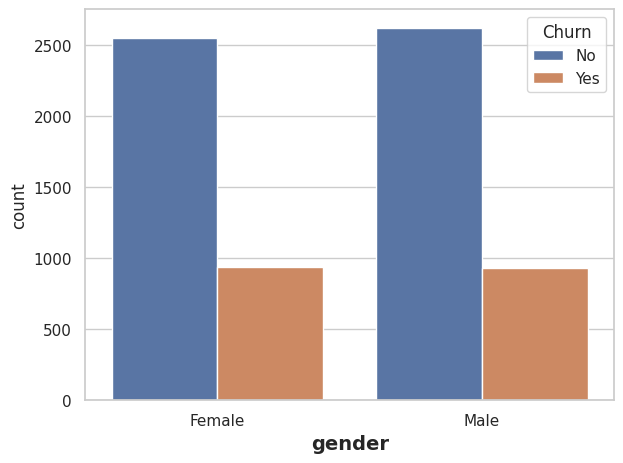

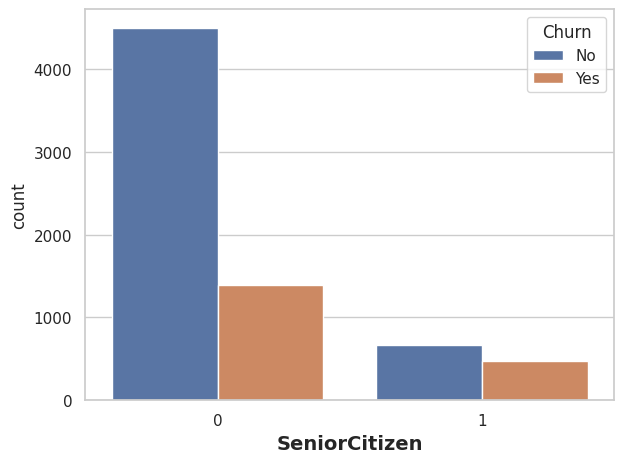

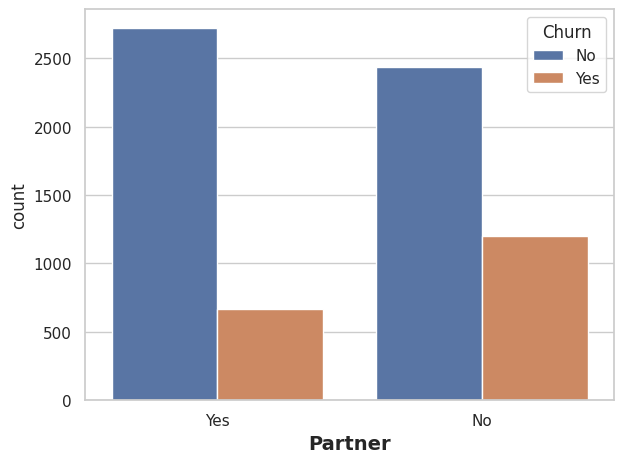

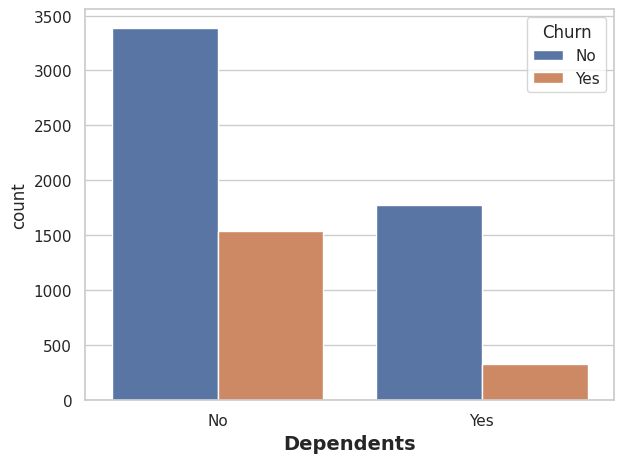

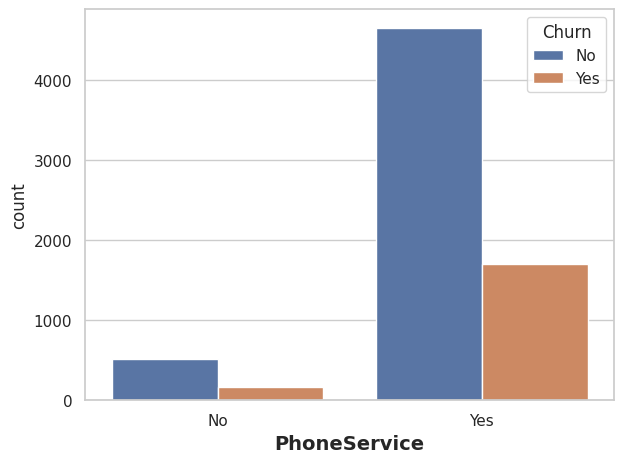

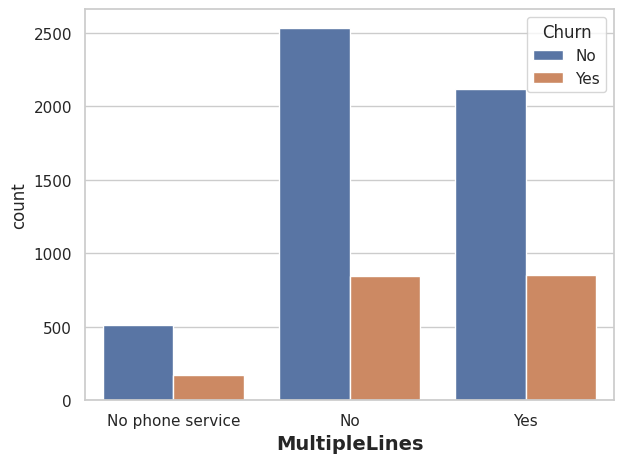

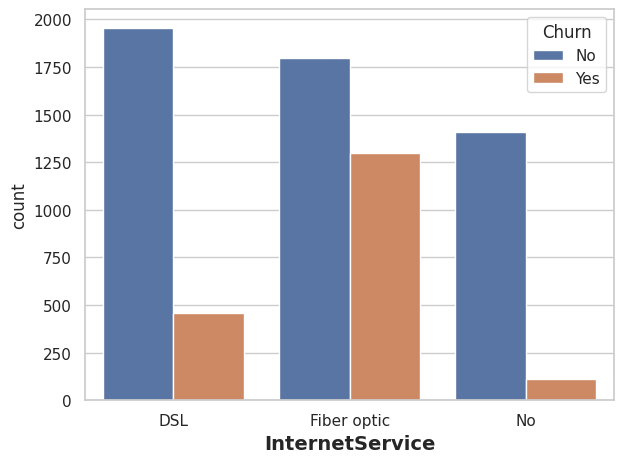

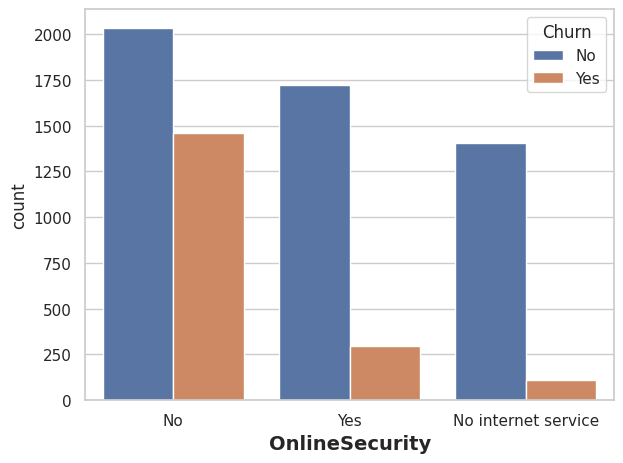

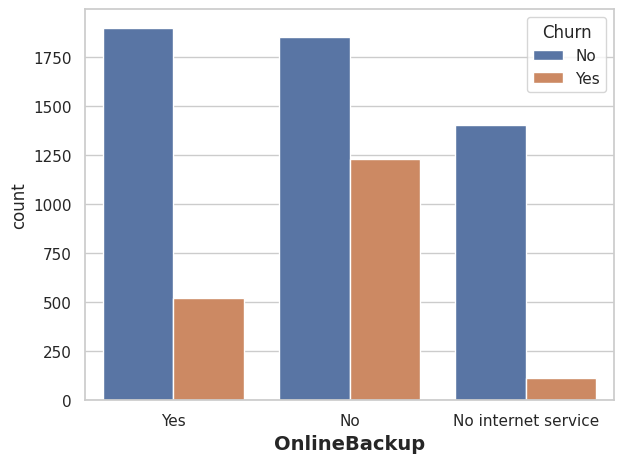

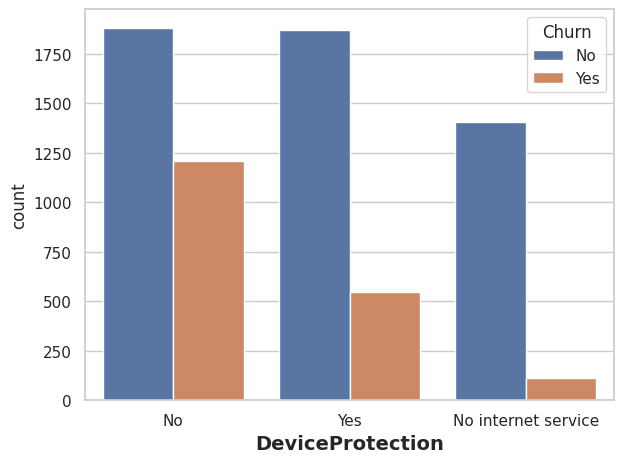

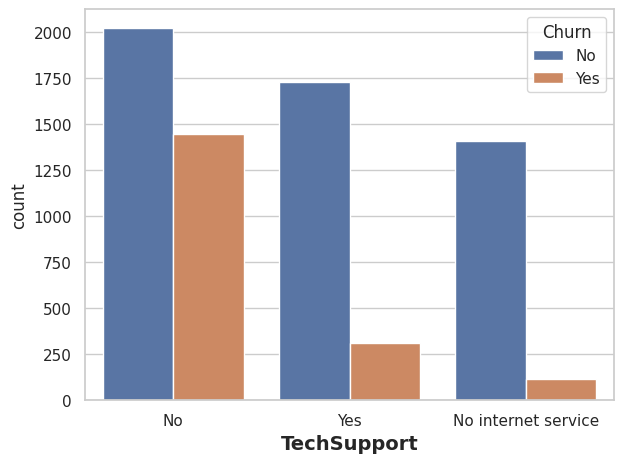

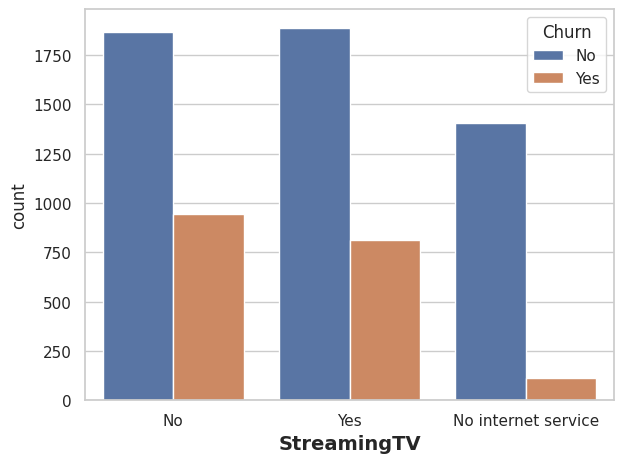

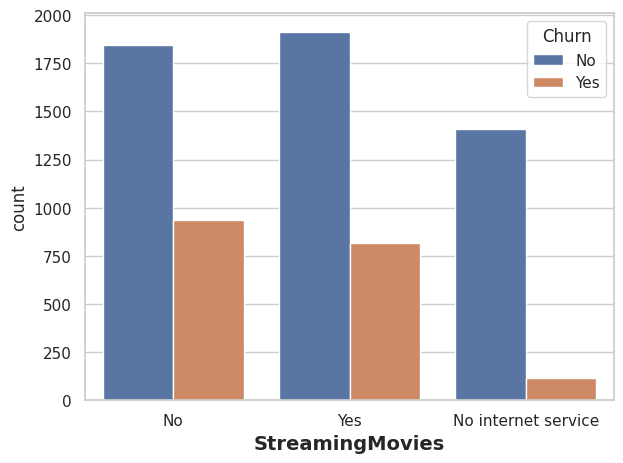

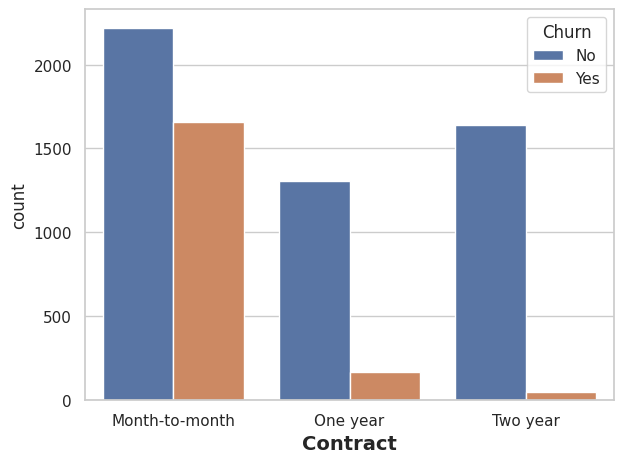

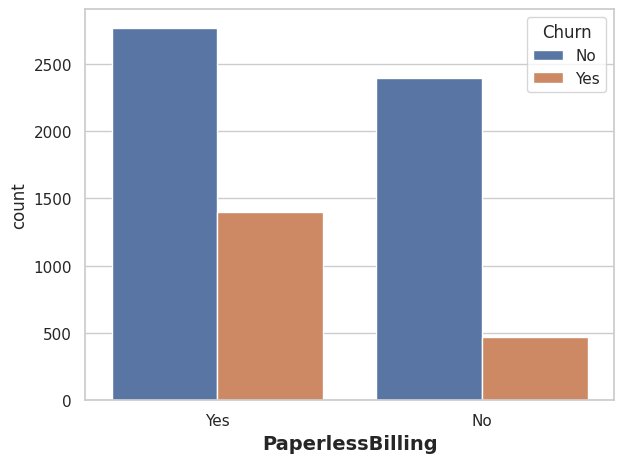

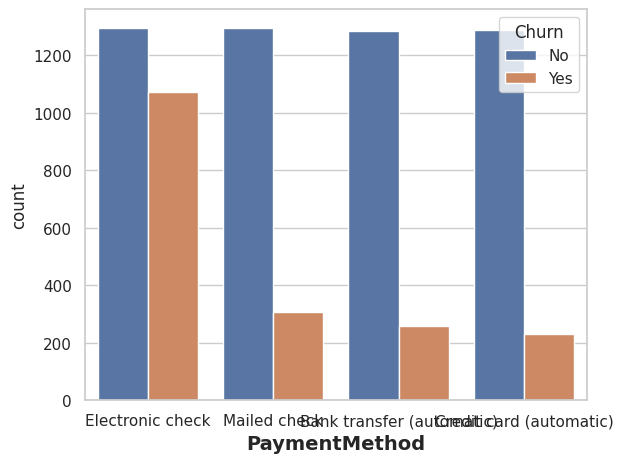

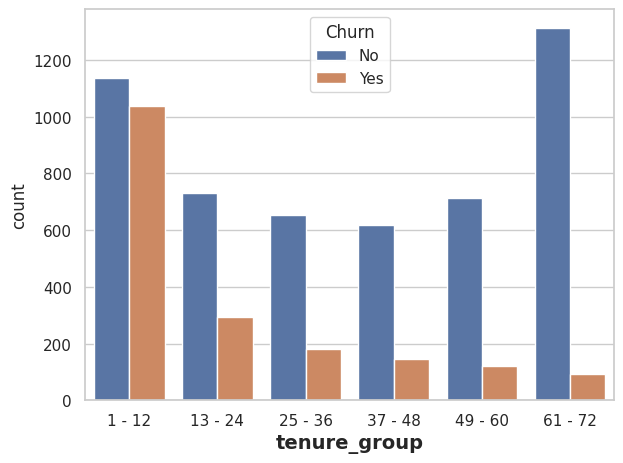

In [24]:
# Plot distribution of individual predictors or features by churn using Univariate Analysis

for i, predictor in enumerate(df1.drop(columns=['Churn', 'TotalCharges', 'MonthlyCharges'])):
    plt.figure(i)
    plt.xlabel(predictor, fontweight='bold', fontsize=14)
    sns.countplot(data=df1, x=predictor, hue='Churn')
    plt.tight_layout()
    plt.show()

In [25]:
# Convert the target varaible Churn into a binary numerical values. Yes=1, No=0
df1["Churn"] = np.where(df1["Churn"]=="Yes", 1, 0)
df1.head()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1 - 12
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,25 - 36
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,1 - 12
3,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,37 - 48
4,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,1 - 12


In [26]:
# Convert categorical columns into numerical columns using one hot encoding.. Numerical values remain unchanged
df_encode = pd.get_dummies(df1, dtype=int, drop_first=True)
df_encode.head()

,SeniorCitizen,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13 - 24,tenure_group_25 - 36,tenure_group_37 - 48,tenure_group_49 - 60,tenure_group_61 - 72
0,0,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0
1,0,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0
2,0,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0
3,0,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
4,0,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0


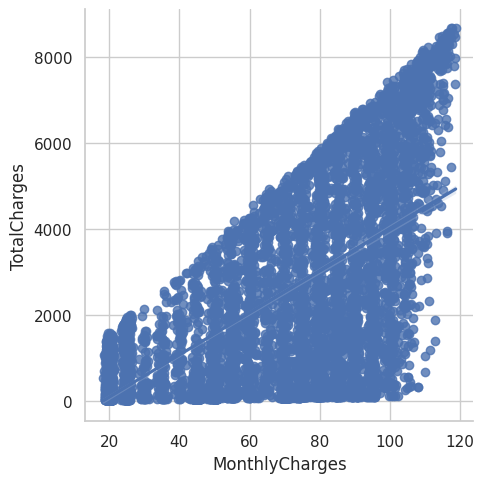

In [27]:
# Visualising relationship between Monthly chaarges and Total Charges
sns.lmplot(data=df_encode, x="MonthlyCharges", y="TotalCharges")

Here we can see, Total charges increase as Month charges increase as expected

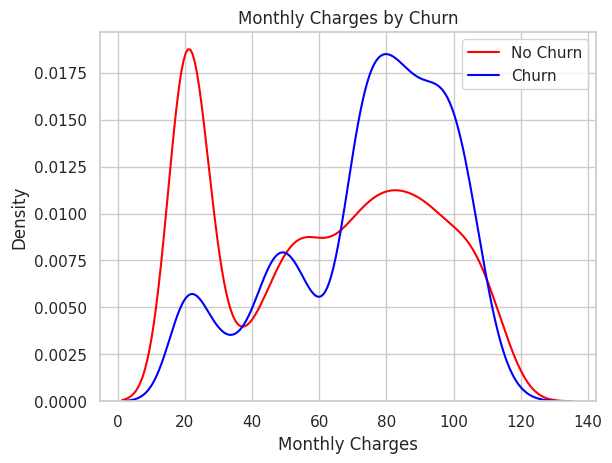

In [28]:
sns.kdeplot(data=df_encode[df_encode["Churn"] == 0],
            x="MonthlyCharges", color="red", label="No Churn")

sns.kdeplot(data=df_encode[df_encode["Churn"] == 1],
            x="MonthlyCharges", color="blue", label="Churn")


plt.xlabel("Monthly Charges")
plt.ylabel("Density")
plt.title("Monthly Charges by Churn")
plt.legend()
plt.show()

Customers with higher monthly charges, particularly around 70–100, appear more concentrated in the churn group. This suggests that higher monthly charges may be associated with a greater likelihood of churn.

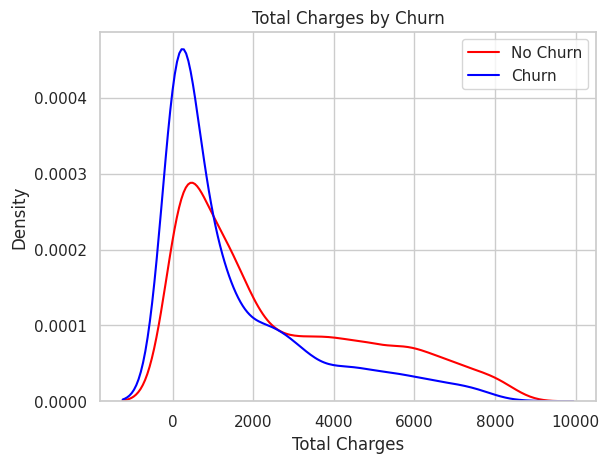

In [29]:
# Plot TotalCharges distribution by churn
sns.kdeplot(data=df_encode[df_encode["Churn"] == 0], x="TotalCharges",
            color="red", label="No Churn")

sns.kdeplot(data=df_encode[df_encode["Churn"] == 1], x="TotalCharges",
            color="blue", label="Churn")

plt.xlabel("Total Charges")
plt.ylabel("Density")
plt.title("Total Charges by Churn")
plt.legend()
plt.show()

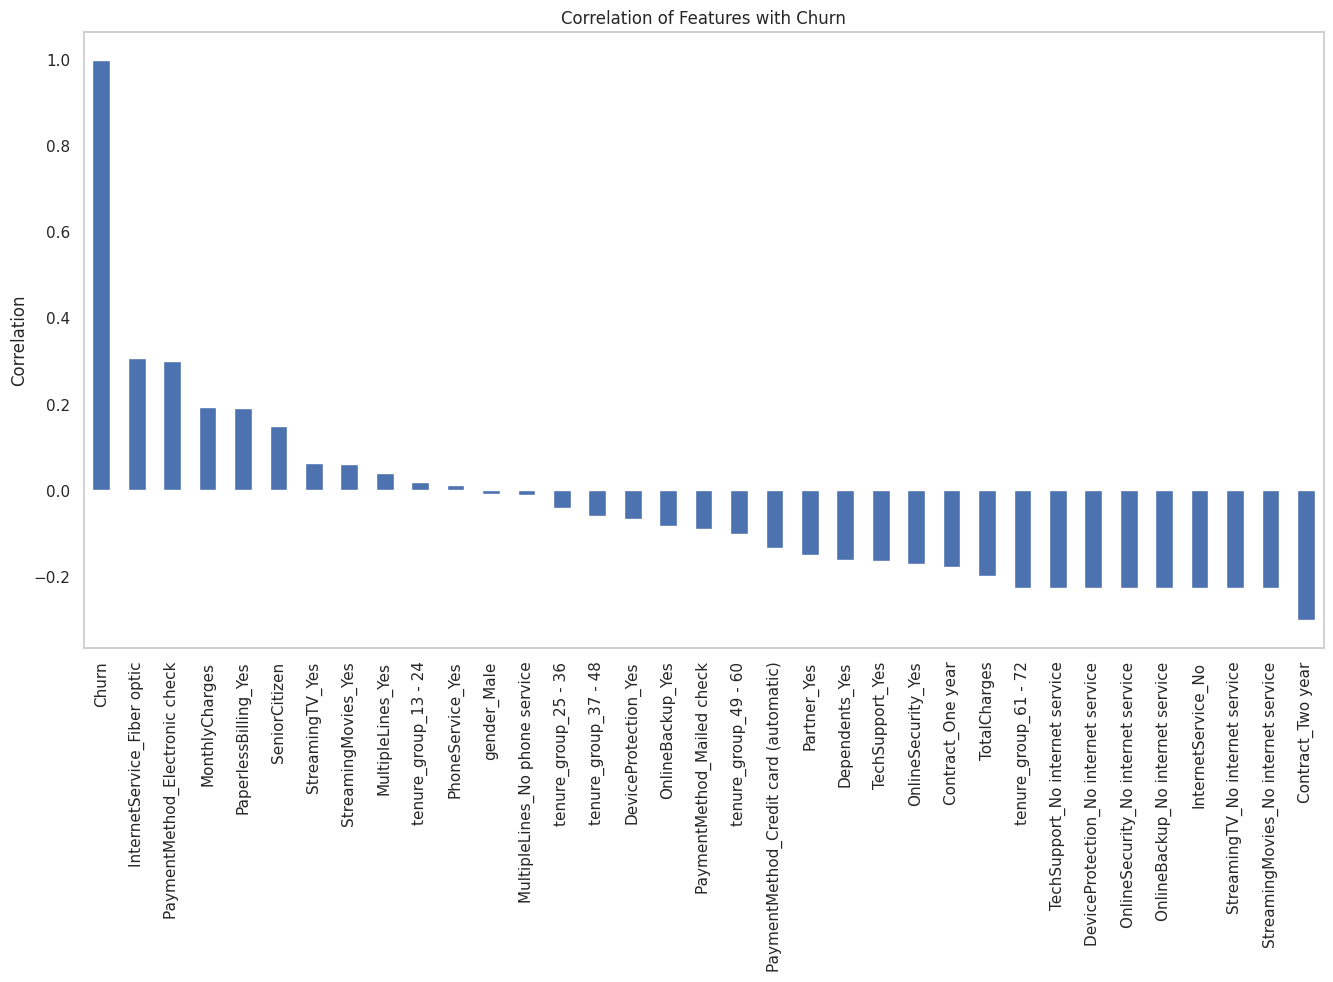

In [30]:
# Correlation of all features with Churn
plt.figure(figsize=(16, 8))
df_encode.corr()['Churn'].sort_values(ascending=False).plot(kind='bar')

plt.ylabel("Correlation")
plt.title("Correlation of Features with Churn")
plt.grid()
plt.show()

### **1. High Churn:**
- Month-to-month contracts are associated with higher churn.
- Customers without online security or tech support tend to have higher churn.
- Customers with shorter tenure are more likely to churn.
- Fiber optic internet customers show relatively high churn.

### **2. Low Churn:**
- Long-term contracts (one-year and two-year) are associated with lower churn.
- Customers with longer tenure tend to have lower churn.
- Customers with online security and tech support tend to have lower churn.

### **3. Low or Weak Correlation:**
- Gender generally has little relationship with churn.
- Phone service and the number of multiple lines generally show weaker relationships with churn than contract type or tenure.

### **Conclusion:**
Contract type, tenure, and additional services appear to be important factors associated with customer churn. These relationships can help guide further analysis and feature selection for the prediction model.

<Axes: >

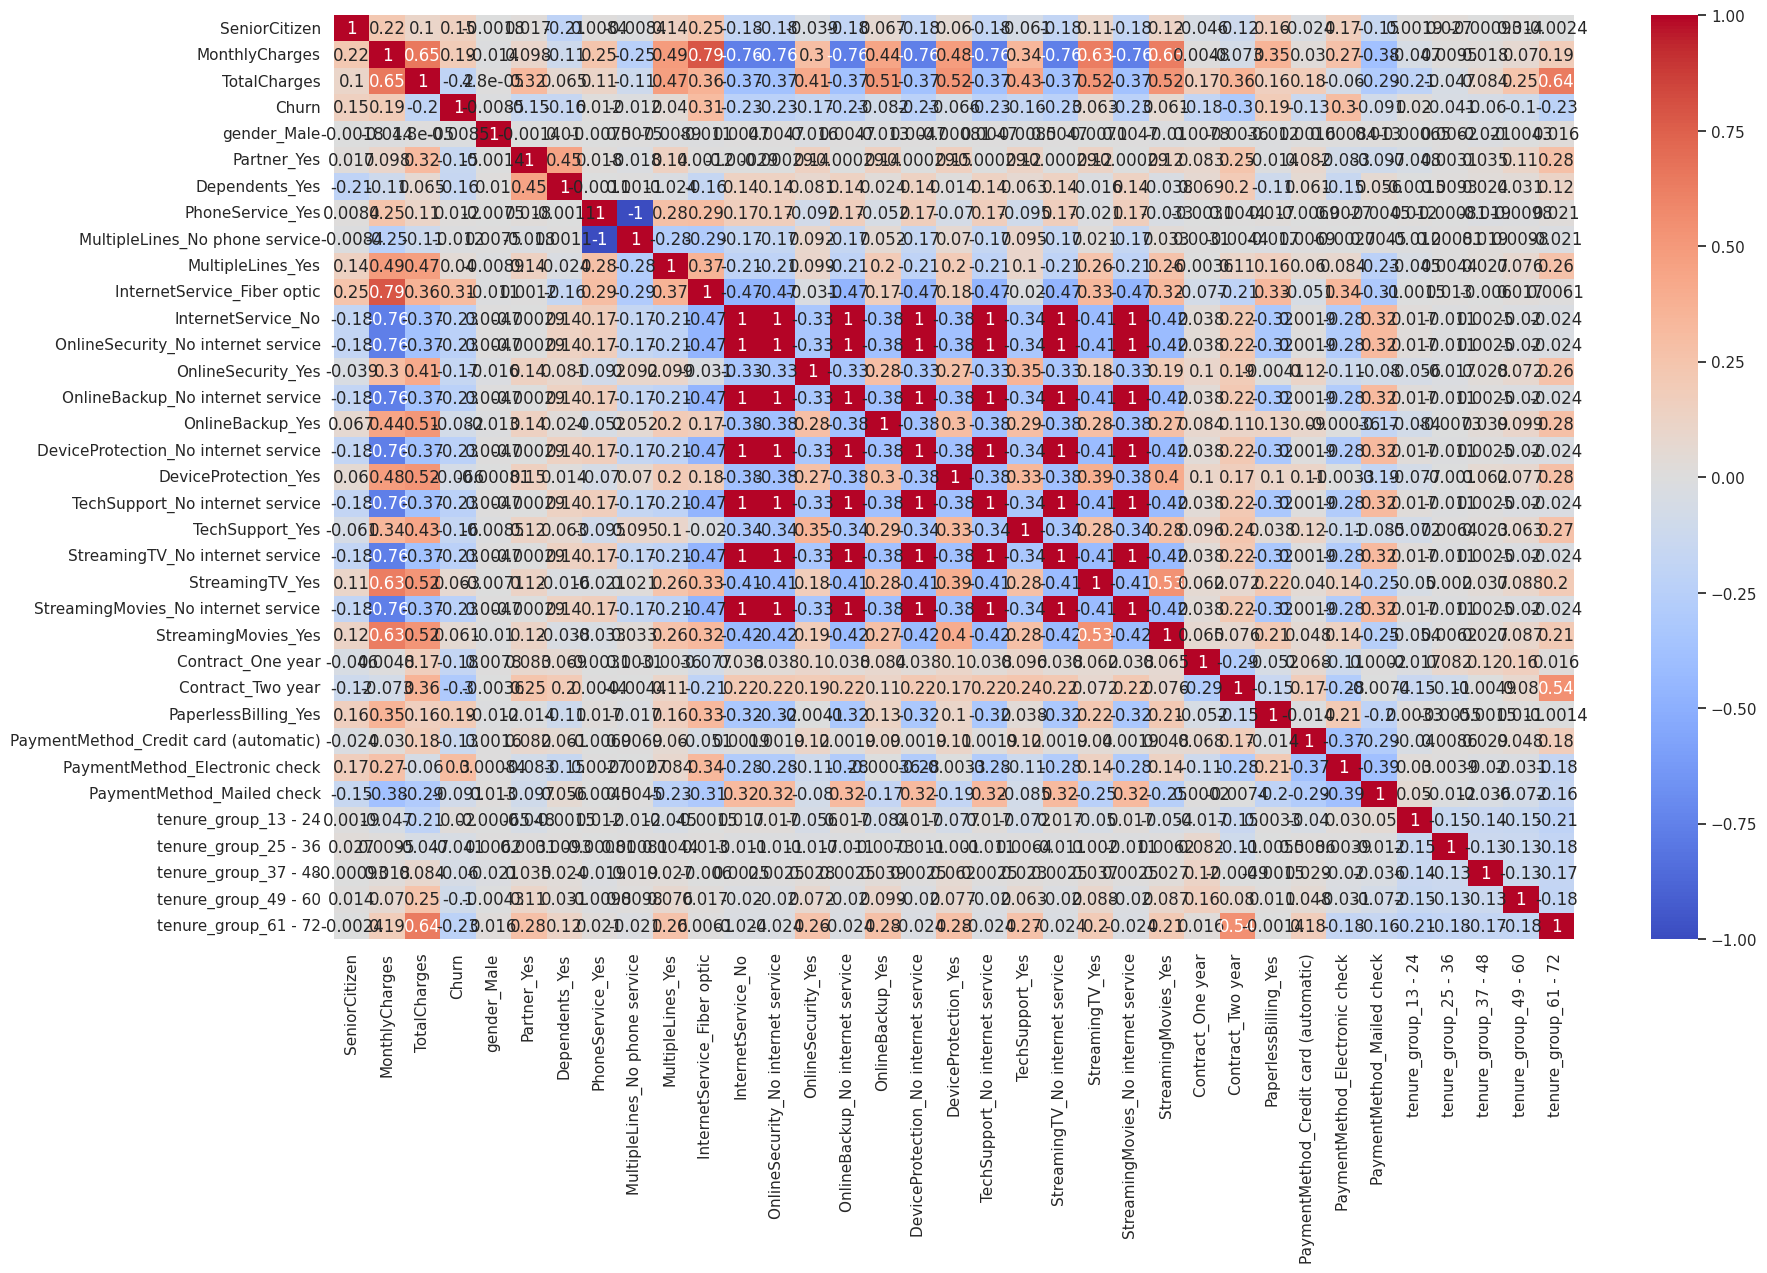

In [31]:
# Correlation Heatmap

plt.figure(figsize=(20,12))
sns.heatmap(df_encode.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)

## **Bi-Variate Analysis**

In [32]:
# Separate customers who stayed and customers who churned
df1_target0 = df1.loc[df1["Churn"] == 0]
df1_target1 = df1.loc[df1["Churn"] == 1]

In [33]:
# Function to plot categorical features by churn
def uniplot(df1, col, title, hue=None):

    temp = pd.Series(data=hue)
    fig, ax = plt.subplots()

    fig.set_size_inches(10, 8)


    ax = sns.countplot(
        data=df1,
        x=col,
        order=df[col].value_counts().index,
        hue=hue,
        palette="bright"
    )

    plt.xticks(rotation=15)
    plt.title(title)
    plt.tight_layout()
    plt.show()

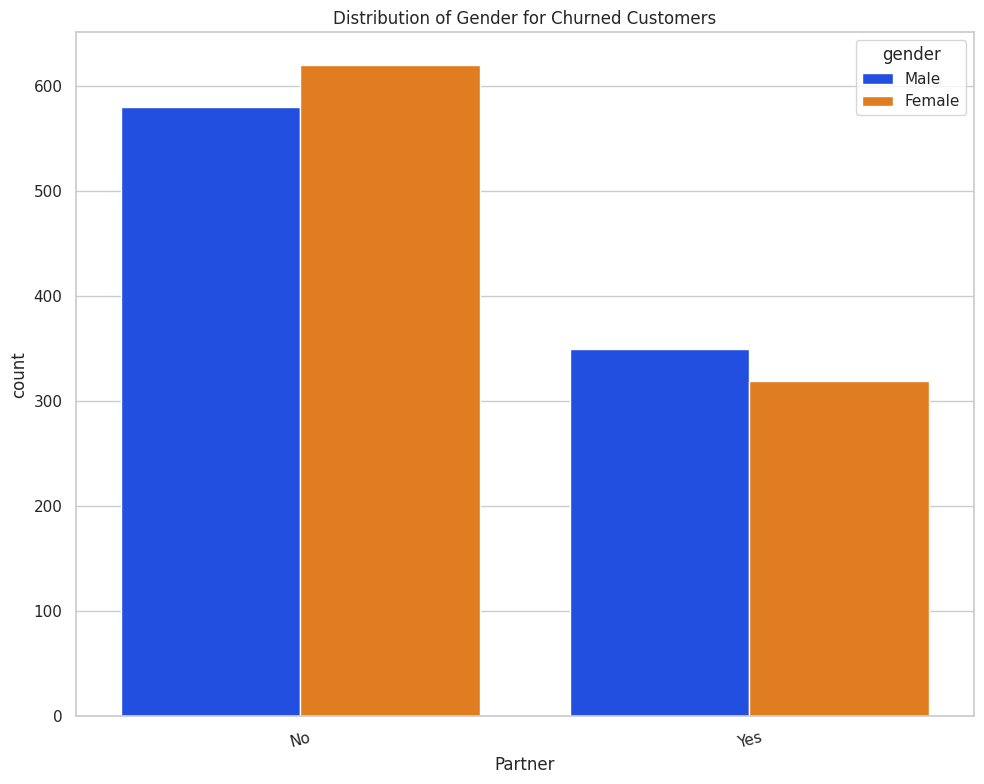

In [34]:
uniplot(df1_target1, "Partner", "Distribution of Gender for Churned Customers", hue="gender")

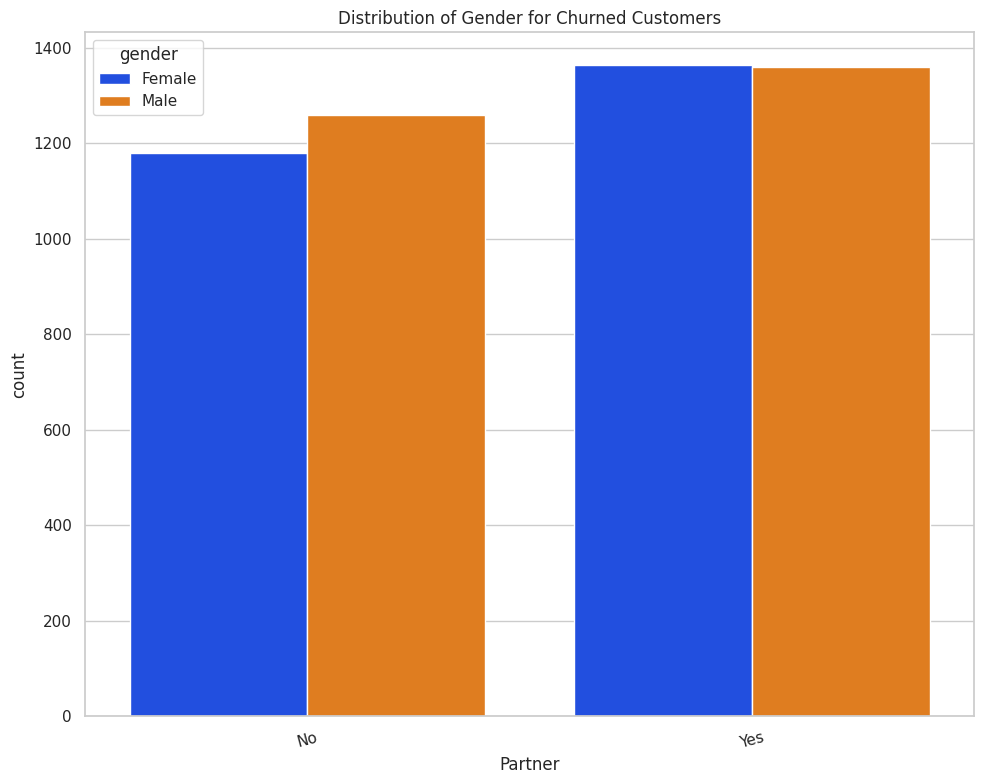

In [35]:
uniplot(df1_target0, "Partner", "Distribution of Gender for Churned Customers", hue="gender")

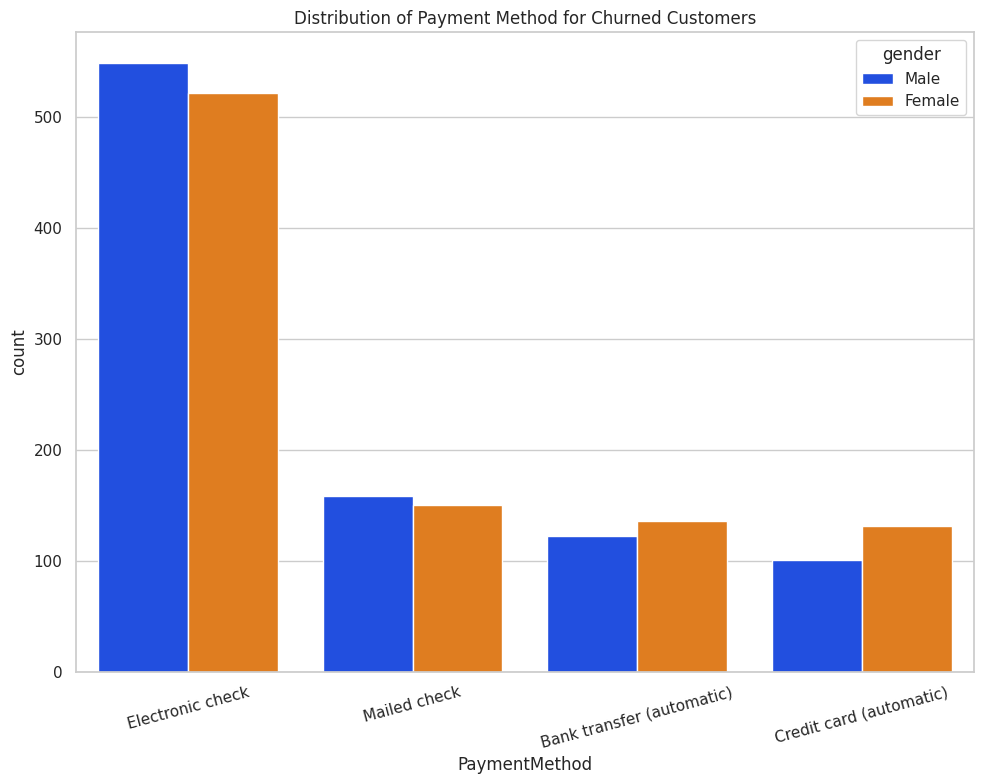

In [36]:
uniplot(df1_target1, "PaymentMethod", "Distribution of Payment Method for Churned Customers", hue="gender")

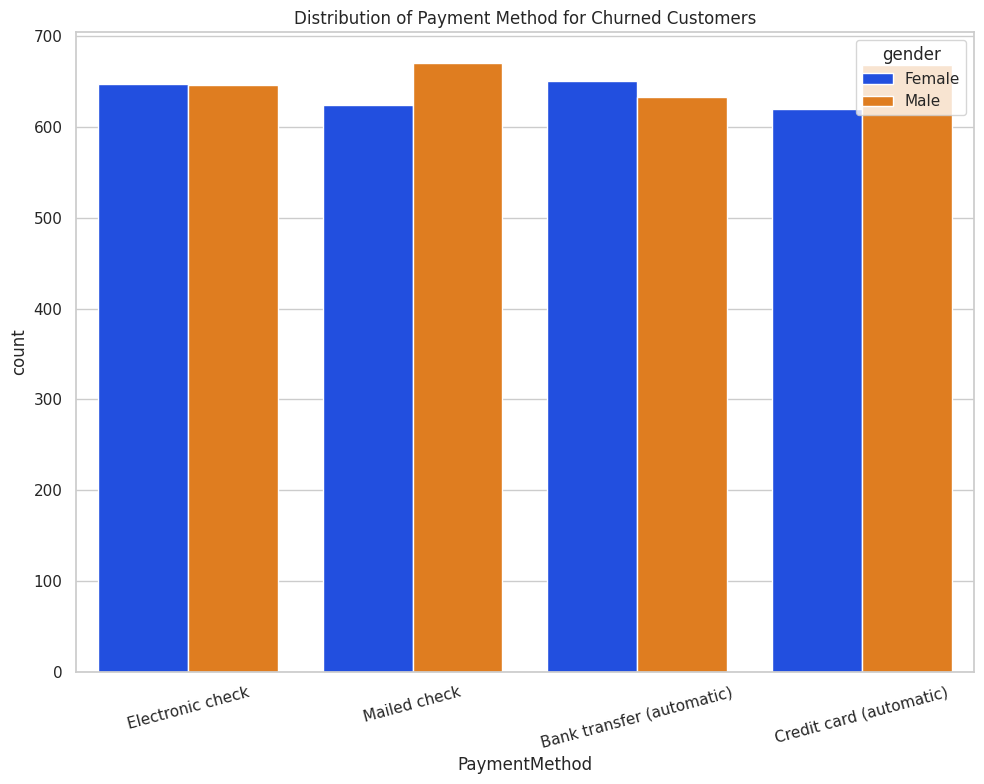

In [37]:

uniplot(df1_target0, "PaymentMethod", "Distribution of Payment Method for Churned Customers", hue="gender")

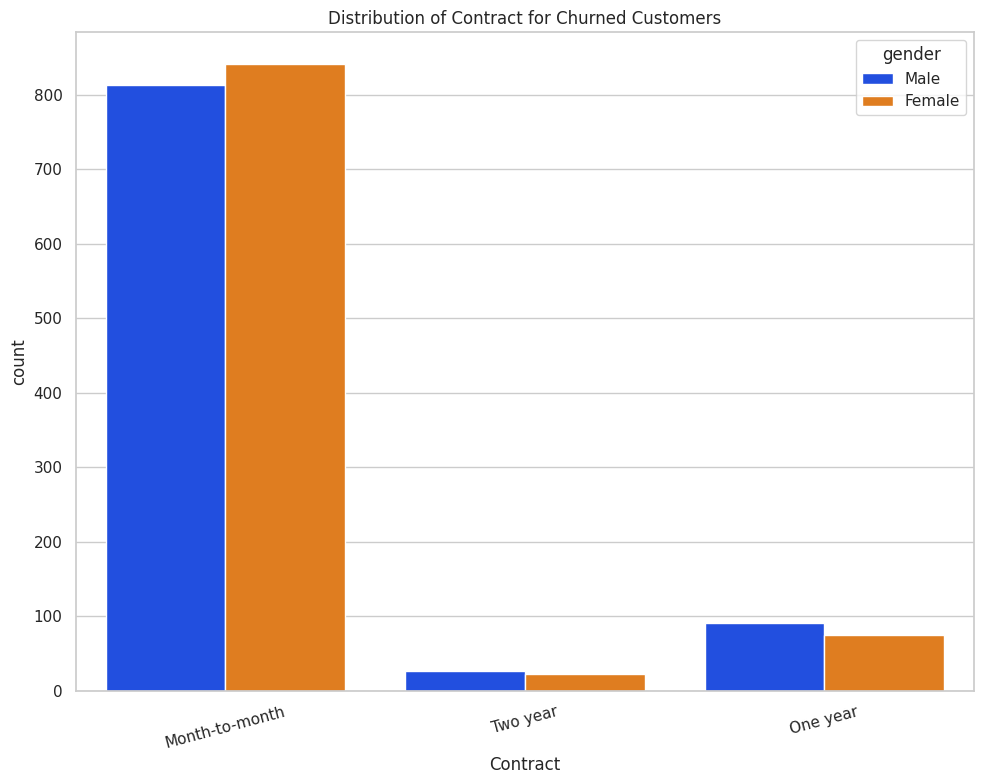

In [38]:
uniplot(df1_target1, "Contract", "Distribution of Contract for Churned Customers", hue="gender")

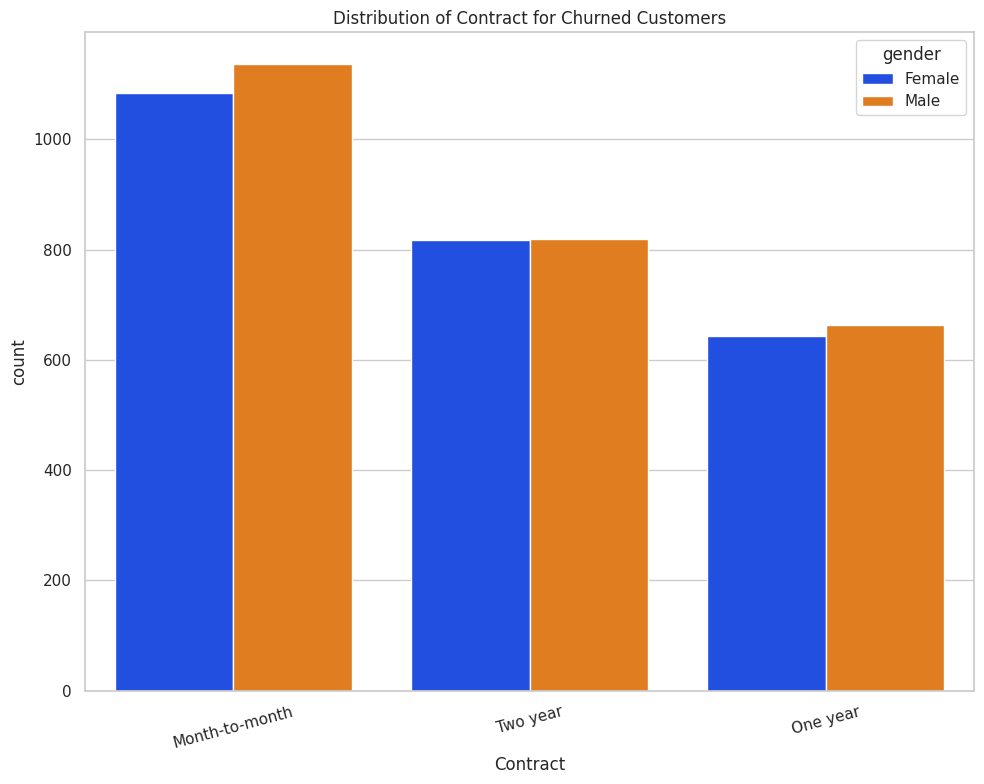

In [39]:
uniplot(df1_target0, "Contract", "Distribution of Contract for Churned Customers", hue="gender")

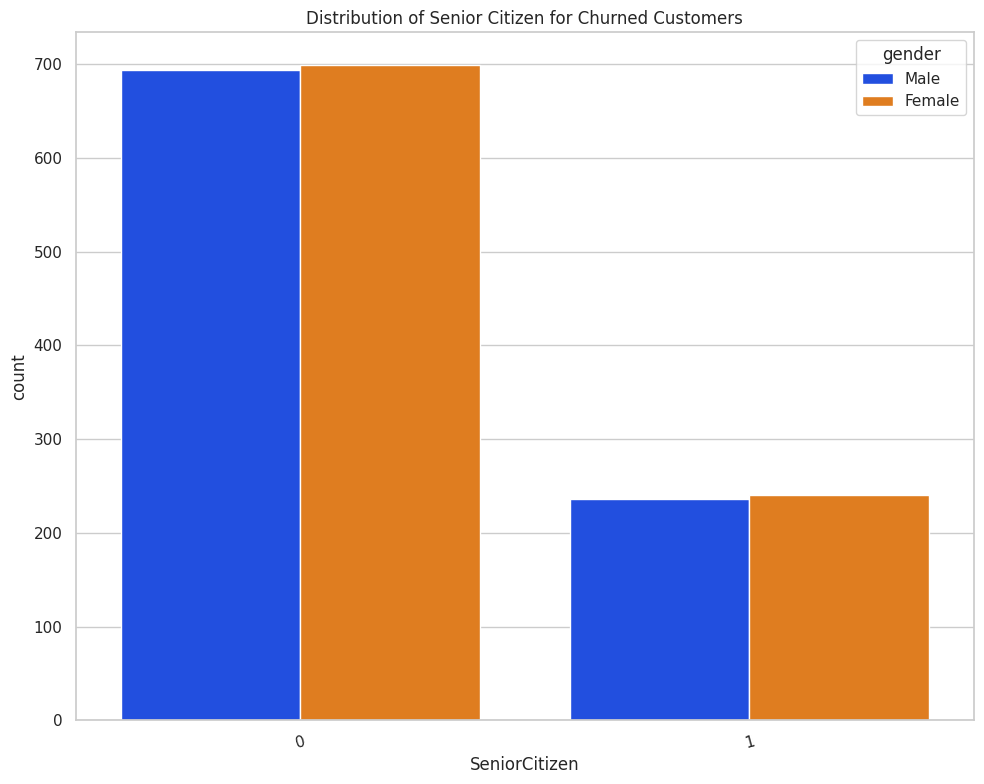

In [40]:
uniplot(df1_target1, "SeniorCitizen", "Distribution of Senior Citizen for Churned Customers", hue="gender")

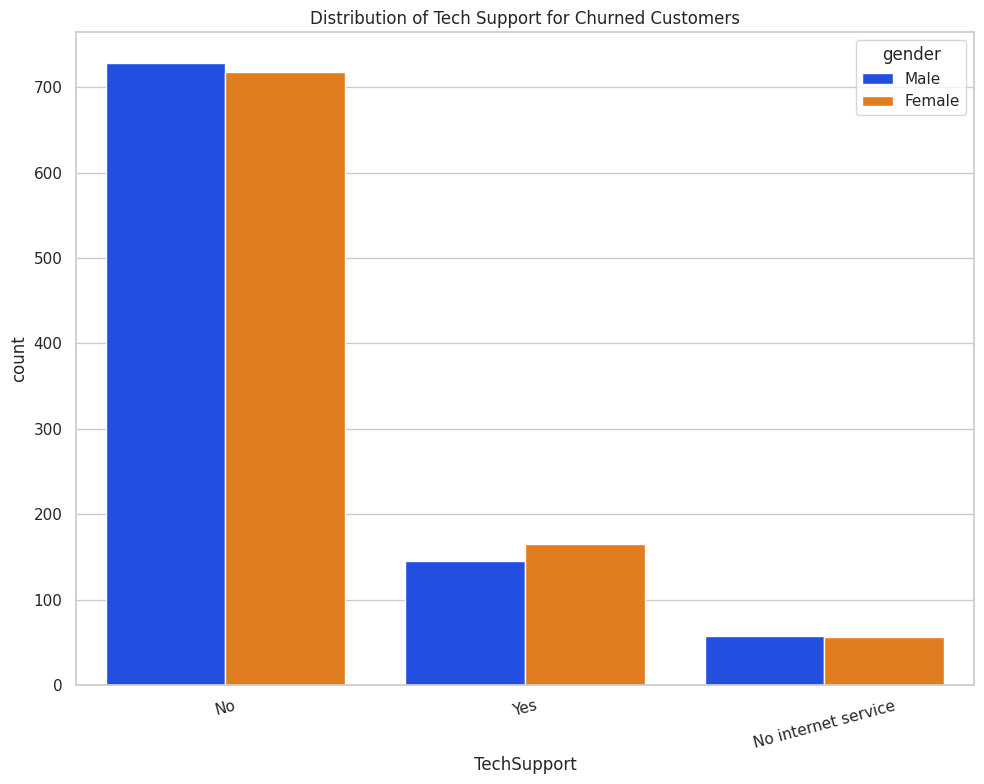

In [41]:
uniplot(df1_target1, "TechSupport", "Distribution of Tech Support for Churned Customers", hue="gender")

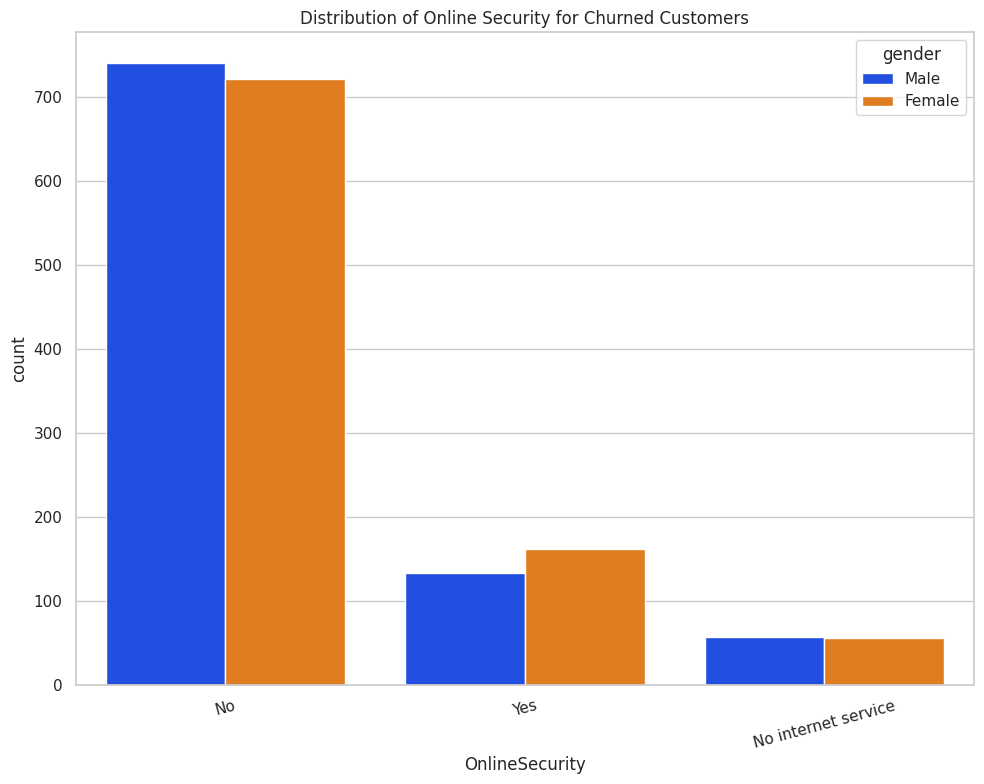

In [42]:
uniplot(df1_target1, "OnlineSecurity", "Distribution of Online Security for Churned Customers", hue="gender")

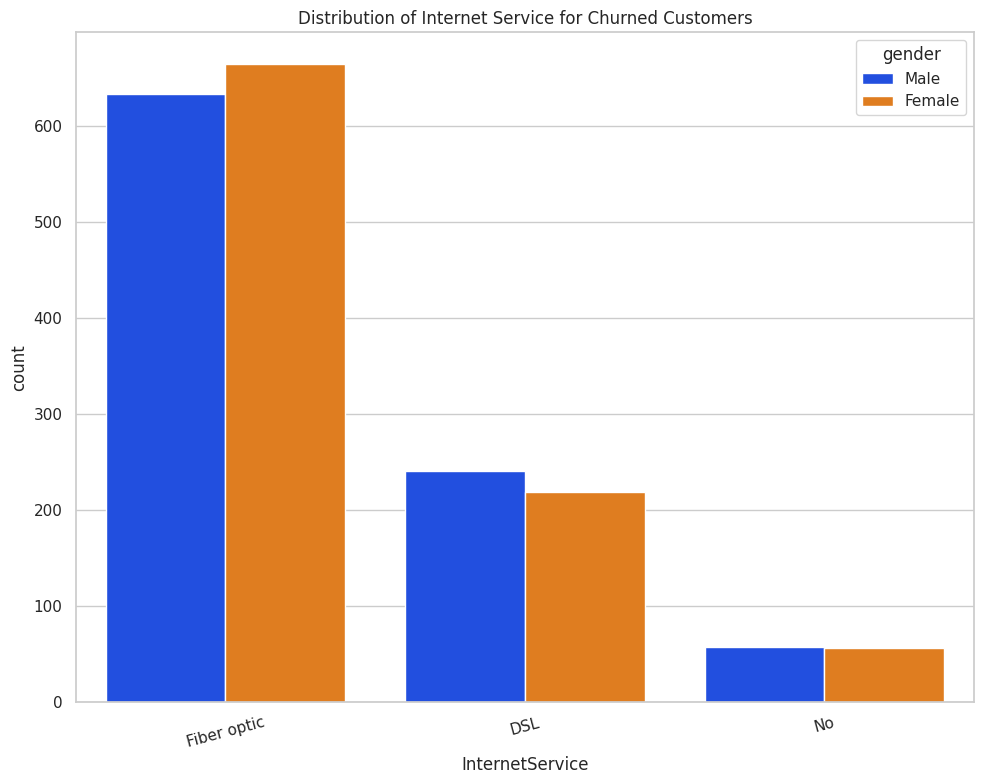

In [43]:
uniplot(df1_target1, "InternetService", "Distribution of Internet Service for Churned Customers", hue="gender")

# CONCLUSION

These are some of the major insights I obtained from the Exploratory Data Analysis (EDA) of the Customer Churn dataset:

1. Payment Method: I observed that customers using Electronic Check have the highest churn count compared with customers using other payment methods.
2. Contract Type: I found that Month-to-month contract customers are more likely to churn than customers with One-year or Two-year contracts.
3. Online Security: I observed that customers without Online Security show higher churn.
4. Tech Support: I found that customers without Tech Support show higher churn.
5. Internet Service: I observed that Fiber Optic customers show a higher churn count than customers in some other internet-service categories.
6. Customer Tenure: I found that customers with shorter tenure are more likely to churn, whereas long-term customers tend to stay.
7. Total Charges: I observed that churned customers are more concentrated at lower TotalCharges values, which may be related to their shorter tenure.
8. Monthly Charges: I found that MonthlyCharges distributions differ between churners and non-churners, suggesting a possible relationship with customer churn.
9. Senior Citizens: I observed that non-senior citizens may have a higher churn count because they represent a larger customer group. I would compare churn rates to determine which age group is more likely to leave.
10. Gender: I found that Gender appears to have a weaker relationship with churn than several service-related features.
11. Phone Service and Multiple Lines: I identified these features as areas for further investigation to determine their relationship with churn.
12. Partner Status: I compared customers with and without partners to identify differences in their churn behaviour.

## Overall EDA Summary

Through my analysis, I identified Contract Type, Tenure, Payment Method, Online Security, Tech Support, and Internet Service as important features to investigate when understanding customer churn. These insights can help identify customer groups that may need additional attention and support customer-retention strategies.

## Model Evaluation

After completing EDA, I can train machine learning models to predict whether a customer is likely to leave the company. I will evaluate their performance using appropriate classification metrics, such as Accuracy, Precision, Recall, F1-score, and ROC-AUC. I will select the best-performing model based on its evaluation results rather than accuracy alone.



In [44]:
# Saving the Encoded Dataset as a CSV File
df_encode.to_csv("df_final.csv", index=False)

In [45]:
# Loading the Final Encoded Dataset
df_final = pd.read_csv("df_final.csv")

# Displaying the first 5 rows
df_final.head()

,SeniorCitizen,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13 - 24,tenure_group_25 - 36,tenure_group_37 - 48,tenure_group_49 - 60,tenure_group_61 - 72
0,0,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0
1,0,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0
2,0,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0
3,0,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
4,0,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0


In [46]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 35 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7032 non-null   int64  
 1   MonthlyCharges                         7032 non-null   float64
 2   TotalCharges                           7032 non-null   float64
 3   Churn                                  7032 non-null   int64  
 4   gender_Male                            7032 non-null   int64  
 5   Partner_Yes                            7032 non-null   int64  
 6   Dependents_Yes                         7032 non-null   int64  
 7   PhoneService_Yes                       7032 non-null   int64  
 8   MultipleLines_No phone service         7032 non-null   int64  
 9   MultipleLines_Yes                      7032 non-null   int64  
 10  InternetService_Fiber optic            7032 non-null   int64  
 11  Inte

In [47]:
import os
print(os.getcwd())

/content


# **3. Model Building**

In [48]:
# Importing required libraries
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from imblearn.combine import SMOTEENN


In [49]:
# Creating X and y varaible
X = df_final.drop("Churn", axis=1)
y = df_final["Churn"]

In [50]:
X.head(3)

,SeniorCitizen,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13 - 24,tenure_group_25 - 36,tenure_group_37 - 48,tenure_group_49 - 60,tenure_group_61 - 72
0,0,29.85,29.85,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0
1,0,56.95,1889.50,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0
2,0,53.85,108.15,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0


In [51]:
y.head(2)

,Churn
0,0
1,0


In [52]:
# Bifurcating the data into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
    )

# **Model: Decision Tree Classifier**

In [53]:
# Initializing the Decision Tree Classifier using the Gini Index with depth of 6 levels

model_dtg = DecisionTreeClassifier(
    criterion="gini",
    random_state=100,
    max_depth=6,
    min_samples_leaf=8
    )

In [54]:
# Training the Decision Tree Classifier
model_dtg.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=6, min_samples_leaf=8, random_state=100)

In [55]:
# Predicting the result of test data
y_pred = model_dtg.predict(X_test)

In [56]:
y_pred[:5]

array([0, 0, 1, 0, 0])

In [57]:
y_test[:5]

,Churn
2476,0
6773,0
6116,1
3047,0
4092,0


In [58]:
# Evaluating the Model Using Accuracy Score
acc = accuracy_score(y_test, y_pred)
acc

0.7683013503909026

In [59]:
# Evaluating using the score() method, which internally predicts results
# using X_test and compares them with the actual values in y_test to calculate accuracy.
acc = model_dtg.score(X_test, y_test)
acc

0.7683013503909026

In [60]:
# Evaluating the Model Using a Classification Report
class_report = classification_report(y_test, y_pred)
print(class_report)

              precision    recall  f1-score   support

           0       0.81      0.90      0.85      1033
           1       0.59      0.41      0.48       374

    accuracy                           0.77      1407
   macro avg       0.70      0.65      0.67      1407
weighted avg       0.75      0.77      0.75      1407



In [61]:
con_mat = confusion_matrix(y_test, y_pred)
con_mat

array([[929, 104],
       [222, 152]])

## **Resample the Training Data to Handle Class Imbalance**

In [62]:
# Applying SMOTEENN to Handle Class Imbalance

# SMOTE (Upsampling): Creates synthetic samples for the minority class (customers who churn).
# ENN (Downsampling/Cleaning): Removes some samples from either class that do not agree with their nearest neighbours.

sm = SMOTEENN()
X_resampled, y_resampled = sm.fit_resample(X, y)

In [63]:
# Comparing the Number of Samples Before and After SMOTEENN
print("Original dataset shape:", X.shape)
print("Resampled dataset shape:", X_resampled.shape)

# Comparing the Original and Resampled Target Distributions
print("\nOriginal Churn Distribution:")
print(y.value_counts())

print("\nResampled Churn Distribution:")
print(y_resampled.value_counts())

Original dataset shape: (7032, 34)
Resampled dataset shape: (5719, 34)

Original Churn Distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64

Resampled Churn Distribution:
Churn
1    3113
0    2606
Name: count, dtype: int64


In [64]:
# Splitting the Resampled Dataset into Training and Testing Sets
xr_train, xr_test, yr_train, yr_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2
)

In [65]:
model_dt_smote = DecisionTreeClassifier(
    criterion="gini",
    random_state=100,
    max_depth=6,
    min_samples_leaf=8
)


In [66]:
model_dt_smote.fit(xr_train, yr_train)

DecisionTreeClassifier(max_depth=6, min_samples_leaf=8, random_state=100)

In [67]:
y_pred_smote = model_dt_smote.predict(xr_test)

In [68]:
# Evaluating the Model Using a Classification Report
class_report_smote = classification_report(yr_test, y_pred_smote)
print(class_report_smote)

              precision    recall  f1-score   support

           0       0.94      0.87      0.90       543
           1       0.89      0.95      0.92       601

    accuracy                           0.91      1144
   macro avg       0.91      0.91      0.91      1144
weighted avg       0.91      0.91      0.91      1144



In [69]:
con_mat_smote = confusion_matrix(yr_test, y_pred_smote)
con_mat_smote

array([[472,  71],
       [ 30, 571]])

In [70]:
print("Classification report before Resampling \n", class_report)
print(" ")
print("\nClassification report after Resampling \n", class_report_smote)

Classification report before Resampling 
               precision    recall  f1-score   support

           0       0.81      0.90      0.85      1033
           1       0.59      0.41      0.48       374

    accuracy                           0.77      1407
   macro avg       0.70      0.65      0.67      1407
weighted avg       0.75      0.77      0.75      1407

 

Classification report after Resampling 
               precision    recall  f1-score   support

           0       0.94      0.87      0.90       543
           1       0.89      0.95      0.92       601

    accuracy                           0.91      1144
   macro avg       0.91      0.91      0.91      1144
weighted avg       0.91      0.91      0.91      1144



In [71]:
# Comparing Confusion Matrices Before and After SMOTEENN
print("Confusion Matrix Before SMOTEENN:\n", con_mat)
print("\nConfusion Matrix After SMOTEENN:\n", con_mat_smote)

Confusion Matrix Before SMOTEENN:
 [[929 104]
 [222 152]]

Confusion Matrix After SMOTEENN:
 [[472  71]
 [ 30 571]]


## **Conclusion**


After applying SMOTEENN, the model's accuracy improved from 77% to 91%, while recall for the churn class increased from 41% to 96%. The confusion matrix also shows that false negatives decreased from 222 to 24, meaning the model missed fewer customers who actually churned. However, both models should be evaluated on the same, untouched test dataset for a fair comparison.

## **Evaluating Other Machine Learning Models for Performance Comparison**


## **Part - A : Original Data**

In [72]:
# Importing other Classification Models for Performance Comparison
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [73]:
# Initializing Multiple Classification Models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=1000, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "KNN": KNeighborsClassifier(),
    "SVM": make_pipeline(StandardScaler(),SVC(class_weight="balanced", random_state=42)),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [74]:
# Training and Evaluating Multiple Classification Models
for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nClassification Report before resampling for {name}")
    print(classification_report(y_test, y_pred))


Classification Report before resampling for Decision Tree
              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1033
           1       0.48      0.49      0.49       374

    accuracy                           0.72      1407
   macro avg       0.65      0.65      0.65      1407
weighted avg       0.73      0.72      0.73      1407


Classification Report before resampling for Random Forest
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1033
           1       0.62      0.46      0.53       374

    accuracy                           0.78      1407
   macro avg       0.72      0.68      0.69      1407
weighted avg       0.77      0.78      0.77      1407


Classification Report before resampling for Logistic Regression
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1033
           1       0.63      0.46      0.53       374


In [75]:
# Comparing the Performance of All Classification Models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1-Score
6,Gradient Boosting,0.796020,0.653710,0.494652,0.563166
2,Logistic Regression,0.785359,0.633333,0.457219,0.531056
1,Random Forest,0.782516,0.623188,0.459893,0.529231
3,KNN,0.772566,0.595745,0.449198,0.512195
4,SVM,0.734897,0.500882,0.759358,0.603613
0,Decision Tree,0.724236,0.481675,0.491979,0.486772
5,Naive Bayes,0.657427,0.427419,0.850267,0.568873


## **Conclusion**

I evaluated seven classification models on the original, imbalanced dataset. Gradient Boosting achieved the highest accuracy of 79.60%, while SVM achieved the highest F1-score of 60.36%. Naive Bayes achieved the highest recall of 85.03%, making it better at identifying customers likely to churn, although its precision was lower. These results show that different models perform differently, so I will compare them with the models trained after applying SMOTEENN to determine whether resampling improves churn prediction.

# **Part B : After Resampling**

In [76]:
# Training and Evaluating Multiple Classification Models
for name, model in models.items():

    model.fit(xr_train, yr_train)

    y_pred_smote = model.predict(xr_test)

    print(f"\nClassification Report after resampling for {name}")
    print(classification_report(yr_test, y_pred_smote))


Classification Report after resampling for Decision Tree
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       543
           1       0.93      0.94      0.94       601

    accuracy                           0.93      1144
   macro avg       0.93      0.93      0.93      1144
weighted avg       0.93      0.93      0.93      1144


Classification Report after resampling for Random Forest
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       543
           1       0.95      0.96      0.96       601

    accuracy                           0.95      1144
   macro avg       0.95      0.95      0.95      1144
weighted avg       0.95      0.95      0.95      1144


Classification Report after resampling for Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       543
           1       0.93      0.95      0.94       601

  

In [77]:
results = []

for name, model in models.items():
    model.fit(xr_train, yr_train)
    y_pred_smote = model.predict(xr_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(yr_test, y_pred_smote),
        "Precision": precision_score(yr_test, y_pred_smote, zero_division=0),
        "Recall": recall_score(yr_test, y_pred_smote, zero_division=0),
        "F1-Score": f1_score(yr_test, y_pred_smote, zero_division=0)
    })
# Display model performance, sorted by Accuracy
results_smote = pd.DataFrame(results)
results_smote = results_smote.sort_values(by="Accuracy", ascending=False)

results_smote

,Model,Accuracy,Precision,Recall,F1-Score
3,KNN,0.956294,0.947967,0.970050,0.958882
1,Random Forest,0.953671,0.950658,0.961730,0.956162
6,Gradient Boosting,0.950175,0.944444,0.961730,0.953009
4,SVM,0.935315,0.927066,0.951747,0.939245
2,Logistic Regression,0.935315,0.929853,0.948419,0.939044
0,Decision Tree,0.933566,0.933884,0.940100,0.936982
5,Naive Bayes,0.921329,0.907496,0.946755,0.926710


## **Conclusion**

After applying SMOTEENN resampling, I evaluated seven classification models to compare their performance on the resampled dataset. KNN achieved the highest accuracy of 95.28% and the highest F1-score of 95.73%. Random Forest also performed well, with an accuracy of 94.68% and an F1-score of 95.18%. KNN achieved a recall of 97.32%, indicating that it identified a large proportion of customers likely to churn. These results show improved performance across the evaluated metrics compared with the original dataset. However, since resampling changes the training data distribution, I will verify these results on an untouched test set with the original class distribution before selecting the final model.